In [1]:
import sys
sys.path.append('../')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.caracteristicas import conjuntos_de_features
from src.modelos import *

df_feat = pd.read_csv('../data/processed/features.csv')
df_seg = pd.read_pickle('../data/processed/dataset_segmentado.pkl')
cols_feat = [c for c in df_feat.columns if c.startswith(('est_', 'psd_', 'wav_', 'stft_'))]
y = df_feat['etiqueta'].values
grupos = df_feat['archivo'].values
todos = conjuntos_de_features(cols_feat)
conjuntos = {k: todos[k] for k in ['B_espectral_clasico', 'C_tiempo_frecuencia']}

_, oof = comparar_semillas(df_feat, y, grupos, conjuntos, semillas=[0])      # puntajes fuera de muestra
t = tabla_oof(df_feat, y, oof)
assert (df_seg['archivo'].values == df_feat['archivo'].values).all() and (df_seg['ventana'].values == df_feat['ventana'].values).all()

In [2]:
for n in conjuntos:
    print('=====', n)
    display(errores_por_clase(t, n))
    display(archivos_problematicos(t, n, top=8))

===== B_espectral_clasico


tipo_B_espectral_clasico,TP,TN,FP,FN,ventanas,tasa_error_%
carpeta_original,,,,,,
Z,0,999,1,0,1000,0.1
O,0,1000,0,0,1000,0.0
N,0,984,16,0,1000,1.6
F,0,944,56,0,1000,5.6
S,963,0,0,37,1000,3.7


,archivo,carpeta_original,tipo_B_espectral_clasico,ventanas_erroneas
0,F009.txt,F,FP,10
1,F060.txt,F,FP,10
2,N005.TXT,N,FP,10
3,S016.txt,S,FN,10
4,F073.txt,F,FP,10
5,F021.txt,F,FP,9
6,F070.txt,F,FP,8
7,S084.txt,S,FN,7


===== C_tiempo_frecuencia


tipo_C_tiempo_frecuencia,TP,TN,FP,FN,ventanas,tasa_error_%
carpeta_original,,,,,,
Z,0,999,1,0,1000,0.1
O,0,1000,0,0,1000,0.0
N,0,992,8,0,1000,0.8
F,0,959,41,0,1000,4.1
S,977,0,0,23,1000,2.3


,archivo,carpeta_original,tipo_C_tiempo_frecuencia,ventanas_erroneas
0,S016.txt,S,FN,10
1,F060.txt,F,FP,10
2,F021.txt,F,FP,8
3,N005.TXT,N,FP,7
4,F070.txt,F,FP,6
5,F086.txt,F,FP,5
6,F009.txt,F,FP,4
7,F073.txt,F,FP,4


In [3]:
cols_clave = ['est_std', 'est_long_linea', 'est_hjorth_movilidad', 'psd_rel_Delta', 'psd_rel_Theta',
              'psd_rel_Beta', 'psd_entropia', 'psd_frec_pico', 'wav_entropia', 'stft_Theta_std']
perfil_de_errores(t, df_feat, 'C_tiempo_frecuencia', cols_clave)

,est_std,est_long_linea,est_hjorth_movilidad,psd_rel_Delta,psd_rel_Theta,psd_rel_Beta,psd_entropia,psd_frec_pico,wav_entropia,stft_Theta_std
tipo,,,,,,,,,,
TN,-0.42,-0.38,-0.04,0.15,-0.25,-0.06,0.04,-0.04,-0.05,0.08
FP,0.62,-0.03,-0.66,0.99,-0.39,-0.35,-0.41,-0.66,-0.50,0.29
FN,0.06,-0.04,-0.17,0.53,-0.33,0.09,-0.39,-0.11,-0.46,-0.18
TP,1.66,1.54,0.21,-0.68,1.02,0.25,-0.13,0.21,0.23,-0.32


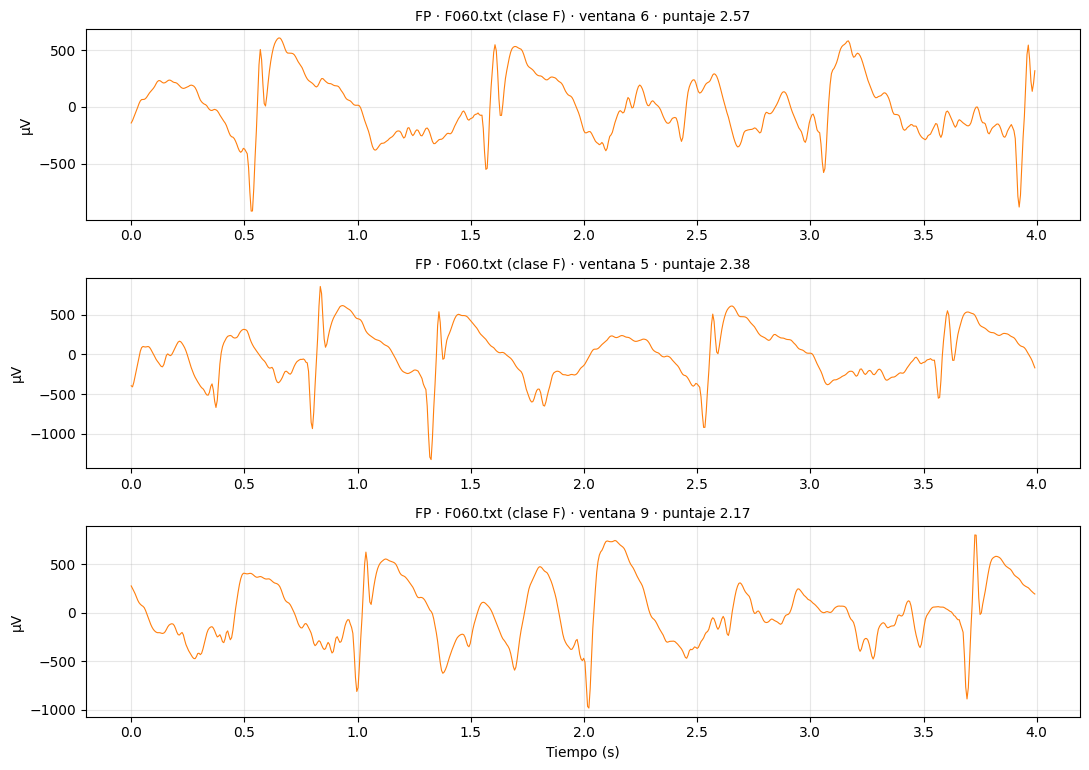

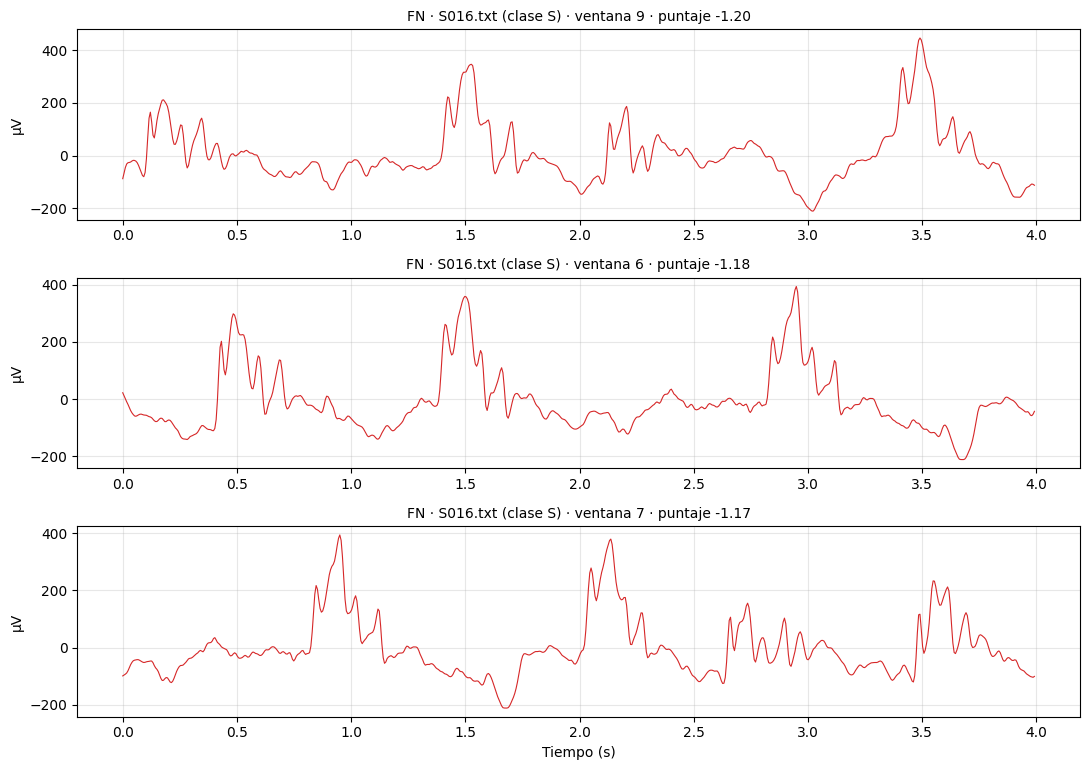

In [4]:
f1 = graficar_errores(df_seg, t, 'C_tiempo_frecuencia', 'FP', n=3)
if f1: f1.savefig('../figuras/ejemplos_FP.png', dpi=200, bbox_inches='tight'); plt.show()
f2 = graficar_errores(df_seg, t, 'C_tiempo_frecuencia', 'FN', n=3)
if f2: f2.savefig('../figuras/ejemplos_FN.png', dpi=200, bbox_inches='tight'); plt.show()

In [5]:
for n in conjuntos:
    g, m = nivel_registro(t, n, umbral_fraccion=0.5)
    print(n, {k: (round(float(v), 3) if isinstance(v, float) else v) for k, v in m.items()})

B_espectral_clasico {'TP': 97, 'TN': 393, 'FP': 7, 'FN': 3, 'sensibilidad': 0.97, 'especificidad': 0.983}
C_tiempo_frecuencia {'TP': 99, 'TN': 395, 'FP': 5, 'FN': 1, 'sensibilidad': 0.99, 'especificidad': 0.988}


In [6]:
from src.dataset import cargar_dataset_completo

raw = cargar_dataset_completo('../data/raw/')
cols_c = todos['C_tiempo_frecuencia']
modelo = entrenar_modelo_final(df_feat, y, cols_c)

for carpeta in ['Z', 'F', 'S']:
    registro = raw[raw.carpeta_original == carpeta].iloc[3]
    r = detectar_crisis(registro['senal'], modelo, cols_c)
    print(f"{registro['archivo']} (clase {carpeta}): {r['decision']} · {r['fraccion_ventanas_crisis']:.0%} de {r['n_ventanas']} ventanas marcadas")

Z004.txt (clase Z): NO CRISIS · 0% de 10 ventanas marcadas
F004.txt (clase F): NO CRISIS · 0% de 10 ventanas marcadas
S004.txt (clase S): CRISIS · 100% de 10 ventanas marcadas
